We have an asset price $(S_t)_{t \ge 0}$ following the Black-Scholes SDE, $\frac{dS_t}{S_t} = \mu dt + \sigma dW_t$ with $(W_t)_t$ the standard brownian motion.

We can expressed the price $V = (F(t,S_t))_{t \in [0,T], S_t \in \mathbb{R}}$ of an option with payoff $\psi(S_T)$ as following:

\begin{equation} 
    {\partial_t F} + r S_t {\partial_x F} + \frac{\sigma^{2}}{2}{S_t}^2 {\partial_xx F} - rV = 0 
\end{equation}
With $r$ the risk free rate of growth.

From the Feynman-Kac formula, for a PDE of the shape:
\begin{equation}
    \partial_t u(x,t) + \mu(x,t) {\partial_x u(x,t)} + \sigma(x,t) {\partial_xx u(x,t)} - V(x,t)u(x,t) + f(x,t) = 0
\end{equation}

We then identify the terms in our case:
\begin{equation}
    \begin{cases}
        \mu(x,t) = rx \\
        \sigma(x,t) = \sigma x \\
        V(x,t) = r \\
        f(x,t) = 0 \\
    \end{cases}
    \\
    \text{  With the terminal condition } u(x,T) = \psi(x)
\end{equation}

*In the case of a call option for example, $\psi$ can be expressed as $\psi(x) = (x - K)_{+}$ with K the strike price and T the maturity of the call*

We then have the solution of the PDE is given by:
$$u(x,t) = \mathbb{E}^{\mathcal{Q}} \left[ g_{\tau}(t,T) \psi(X_T) + \int_{t}^{T} g_s(t,T)f(X_{\tau}, \tau) \mid X_t = x  \right]$$

Where $\mathcal{Q}$ in our case, is the risk-neutral measure and with $g_{\kappa} (a,b) = \exp(-\int_{a}^{b} V(X_{\tau}, \tau) d \tau)$

By plugging our values for the BS PDE, we then have a general solution for the price of an option:
$$u(x,t) = \mathbb{E}^{\mathcal{Q}} \left[ \exp(-r(T - t))\psi(X_T) \mid X_t = x \right]$$

Note that this result could have been optained by simply assuming $\Phi$ is a self-financed strategy that simulates $\psi$ (We have the existence of such a strategy under the Black-Scholes hypothesis [poly lamberton Théorème 3.2]) and by showing that the discounted portfolio $V(\Phi)$ is a martingale under $\mathcal{Q}$ we get to $V_t = \mathbb{E}^{\mathcal{Q}} \left[ \exp(-r(T - t))\psi(S_T) \mid \mathcal{F}_t \right]$ with $\{ \mathcal{F}_t \}_{t \ge 0}$ the natural filtration of the standard Brownian motion under $\mathcal{Q}$.

[ici je pourrais rajouter la preuve que j'ai donné au tableau si besoin].

### The European call option
In the case of a call option (i.e $\psi(x) = (x - K)_{+}$) continuing from the conditional expectation expression we can derive a closed form solution for the price of a call option:
- let $\theta = (T - t)$ the time to marurity of the call.
- $d_{1} = \frac{\log({S_t}/K) + \theta (r + {\sigma}^{2}/2)}{\sigma \sqrt(\theta)}$
- $d_{2} = d_{1} - \sigma \sqrt(\theta)$

The price $F$ of a call, for the underlying of price $S_t$ at time $t$, with a strike of $K$, is then given by:
$$F(t,S_t) = S_t N(d_{1}) - \exp(-r \theta) K N(d_{2})$$
with $N$ the cdf of the standard centered normal distribution.

[je pourrais également ajouter la preuve ici pour trouver le prix à partir de l'éspèrance].

We can compare the approximation of the expectancy given by the Feynman-Kac formula via a Monte Carlo simulation and the exact price given by the closed form formula.

In [1]:
#imports 
import numpy as np
from scipy.stats import norm
import matplotlib.pyplot as plt

#constants
r = 0.02
sigma = 0.2
T = 1

In [3]:
def call_payoff(S,K):
    V = S - K
    return np.array([x if x>0 else 0 for x in V])

def brownian_path(num_paths, size, T=T):
    dt = T/(size+1)
    B = np.array(np.random.normal(0,np.sqrt(dt), (num_paths, size)), dtype=np.float32)
    W0 = np.zeros(shape=(num_paths,1), dtype=np.float32)
    W = np.concatenate([W0 ,np.cumsum(B, axis=1, dtype=np.float32)], axis=1, dtype=np.float32)
    return W

def S_path(S0, W_path, r=r, sigma=sigma, T=T, chunk_size=None, full_path=True):
    if not isinstance(S0, (int, float)):
        assert len(S0) == W_path.shape[0], "S0 and W_path must have the same number of paths"
    num_paths, size = W_path.shape
    dt = T / size

    W_lagged = np.concatenate([np.zeros((num_paths, 1)), W_path[:, :-1]], axis=1, dtype=np.float32)
    dW = (W_path - W_lagged)[:, 1:]          

    S0 = np.broadcast_to(np.asarray(S0, dtype=np.float32), (num_paths,)).copy()

    if chunk_size is None:
        chunk_size = size - 1

    if full_path:
        S = np.empty((num_paths, size), dtype=np.float32)
        S[:, 0] = S0
        current = S0.copy()
        for start in range(0, size - 1, chunk_size):
            end = min(start + chunk_size, size - 1)
            dW_chunk = dW[:, start:end]                     
            growth_chunk = 1 + r * dt + sigma * dW_chunk
            cum_chunk = np.cumprod(growth_chunk, axis=1)
            S[:, start+1:end+1] = current[:, None] * cum_chunk
            current = S[:, end]                             
        return S, S[:, -1]
    else:
        S = S0.copy()
        for start in range(0, size - 1, chunk_size):
            end = min(start + chunk_size, size - 1)
            dW_chunk = dW[:, start:end]
            growth_chunk = 1 + r * dt + sigma * dW_chunk
            S *= np.prod(growth_chunk, axis=1)
        return S


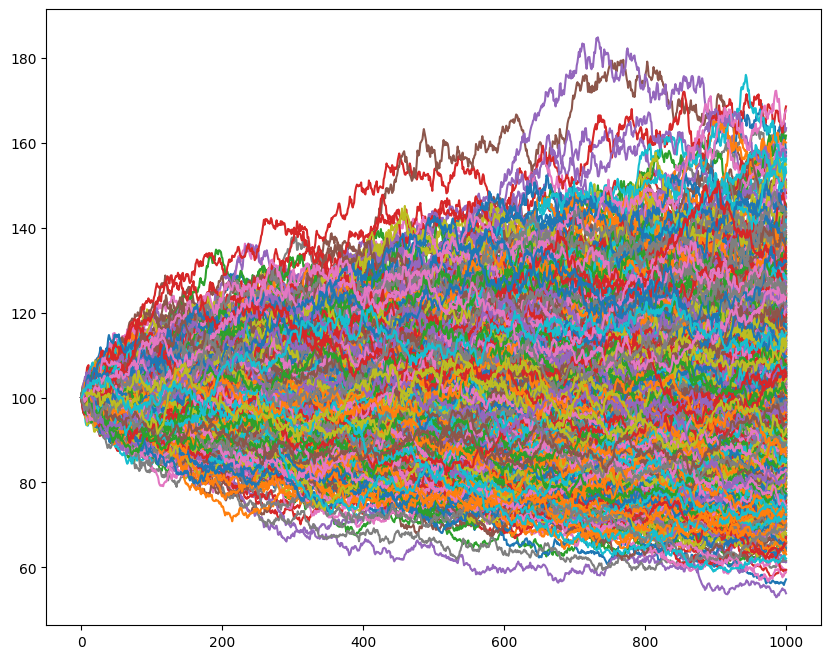

In [4]:
n = 1000
k = 1000
plt.figure(figsize=(10,8))

S0 = [100]*n
W = brownian_path(n,k)
S,_ = S_path(S0,W)

for i in range(n):
    plt.plot(S[i,:])


In [5]:
#we price our calls at time t=0
def monte_carlo_pricer(S0, num_paths, num_steps, K, time_to_maturity, chunk_size=1000):
    S0_vector = np.array([S0]*num_paths)
    W = brownian_path(num_paths=num_paths, size=num_steps)
    S_terminal = S_path(S0=S0_vector, W_path=W, full_path=False, chunk_size=chunk_size)
    payoff = call_payoff(S=S_terminal, K=K)

    outcomes = np.exp(-r*time_to_maturity)*payoff
    return np.mean(outcomes)

def ana_call_price(St, K, time_to_maturity=T, mu=r, sigma=sigma):
    d1 = (np.log(St/K)+ time_to_maturity*(r + (sigma**2)/2))/(sigma*np.sqrt(time_to_maturity))
    d2 = d1 - (sigma*np.sqrt(time_to_maturity))

    F = norm.cdf
    price = St*F(d1) - np.exp(-r*time_to_maturity)*K*F(d2)
    return price

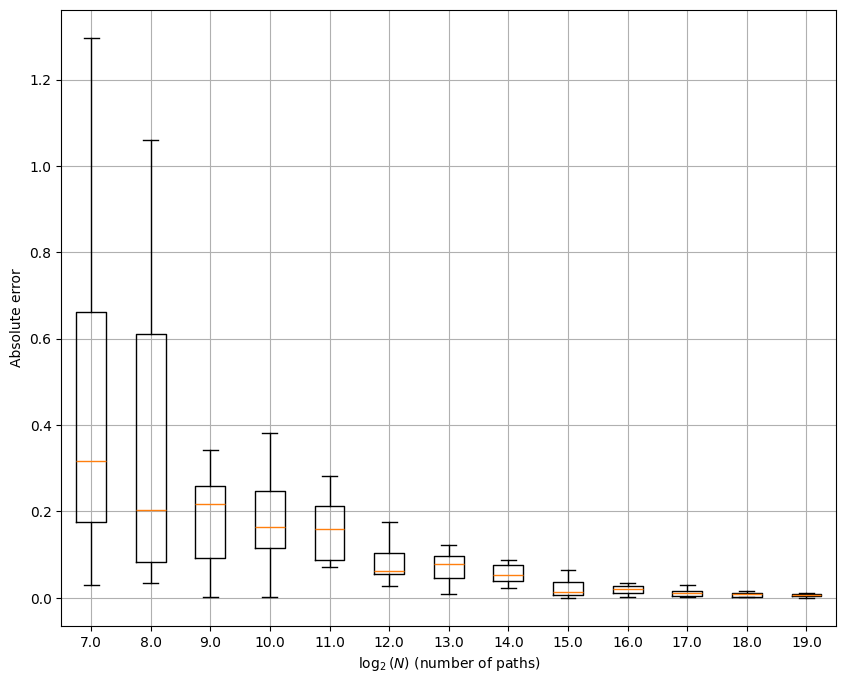

In [32]:
S0 = 100
K = 120
steps = 1000

N = 2**np.arange(7,20)

num_trials = 10  
errors = []
exact_price = ana_call_price(S0, K)

for n in N:
    trial_errors = []

    for _ in range(num_trials):
        mc_price = monte_carlo_pricer(
            S0,
            n,
            steps,
            K,
            T,
            chunk_size=100
        )

        error = abs(mc_price - exact_price)
        trial_errors.append(error)
    errors.append(trial_errors)


plt.figure(figsize=(10,8))
plt.boxplot(
    errors,
    positions=np.log2(N),
    widths=0.5,
    showfliers=False
)

plt.xlabel(r"$\log_2(N)$ (number of paths)")
plt.ylabel("Absolute error")

plt.grid(True, which="both")
plt.show()

[On voit assez clairement la convergence à mesure qu'on augmente le nombre de chemins différents de prix]

### The Geometric Asian call option
We define its payoff depending on the geometric average over the full price path $\psi(S_T) = (\exp(\frac{1}{T}\int_{0}^{T}S_u du) - K)_{+}$.
These options also have a closed form solution under he black scholes model:

- $\sigma_G = \sigma \sqrt{\frac{(n+1)(2n+1)}{6n^2}}$
- $b = \left(r - \frac{\sigma^2}{2}\right)\frac{n+1}{2n} + \frac{\sigma_G^2}{2}$
- $d_{1} = \frac{\log(S_0/K) + T\left(b + \frac{\sigma_G^2}{2}\right)}{\sigma_G \sqrt{T}}$
- $d_{2} = d_{1} - \sigma_G \sqrt{T}$

And then we have $C$ the call price such that:
$$C = S_0 e^{(b-r)T} N(d_{1}) - K e^{-rT} N(d_{2}).$$


In [25]:
def monte_carlo_geom_asian_call(S0, num_paths, num_steps, K, time_to_maturity, chunk_size=1000, r=r):
    S0_vector = np.array([S0]*num_paths)
    W = brownian_path(num_paths, num_steps, T=time_to_maturity)
    S, _ = S_path(S0_vector, W, chunk_size=chunk_size)
    
    average = np.exp(np.mean(np.log(S[:, 1:]), axis=1))
    payoff = call_payoff(average, K)
    
    return np.mean(np.exp(-r*time_to_maturity)*payoff)

def geom_asian_call_price(S0, K, num_steps, time_to_maturity=T, r=r, sigma=sigma):
    T = time_to_maturity
    n = num_steps
    sigma_G = sigma * np.sqrt((n + 1) * (2 * n + 1) / (6 * n**2))
    b = 0.5 * (r - sigma**2 * (n + 1) / (2 * n)) + 0.5 * sigma_G**2

    d1 = (np.log(S0 / K) + (b + 0.5 * sigma_G**2) * T) / (sigma_G * np.sqrt(T))
    d2 = d1 - sigma_G * np.sqrt(T)

    price = S0 * np.exp((b - r) * T) * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)
    return price

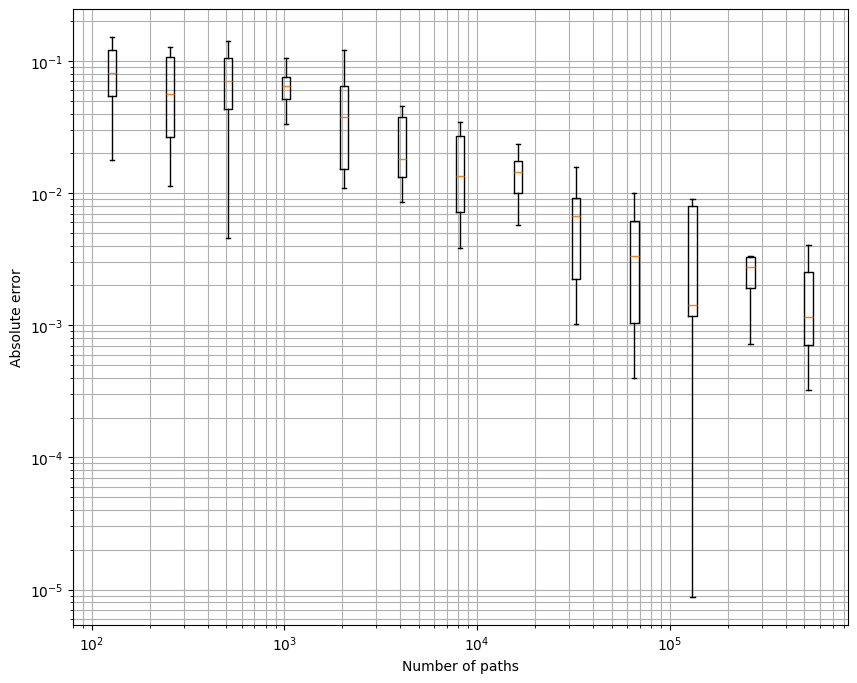

In [35]:
S0 = 100
steps = 1000
K = 120
T = 1

N = 2**np.arange(7,20)

num_trials = 10
exact_price = geom_asian_call_price(S0,K,steps,T)
errors = []

for n in N:
    trial_errors = []

    for _ in range(num_trials):
        mc_price = monte_carlo_geom_asian_call(S0,n,steps,K,T,chunk_size=100)
        error = np.abs(mc_price - exact_price)
        trial_errors.append(error)
    errors.append(trial_errors)

plt.figure(figsize=(10,8))
plt.boxplot(
    errors,
    positions=N,
    widths=N*0.1,
    showfliers=False
)

plt.xscale("log")
plt.yscale("log")
plt.xlabel("Number of paths")
plt.ylabel("Absolute error")
plt.grid(True, which="both")
plt.show()